<a href="https://colab.research.google.com/github/bhagyshrilagade411-debug/MLOPS/blob/main/ML4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

K = 1 Accuracy = 0.989
K = 2 Accuracy = 0.967
K = 3 Accuracy = 0.956
K = 4 Accuracy = 0.956
K = 5 Accuracy = 0.956
K = 6 Accuracy = 0.956
K = 7 Accuracy = 0.956
K = 8 Accuracy = 0.956
K = 9 Accuracy = 0.956
K = 10 Accuracy = 0.956
K = 11 Accuracy = 0.956
K = 12 Accuracy = 0.956
K = 13 Accuracy = 0.956
K = 14 Accuracy = 0.956
K = 15 Accuracy = 0.956
Best K: 1


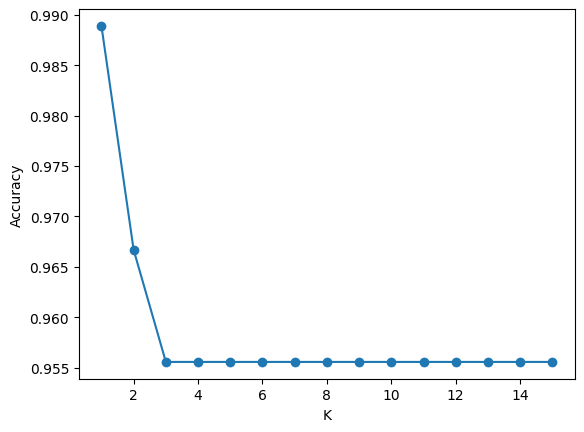

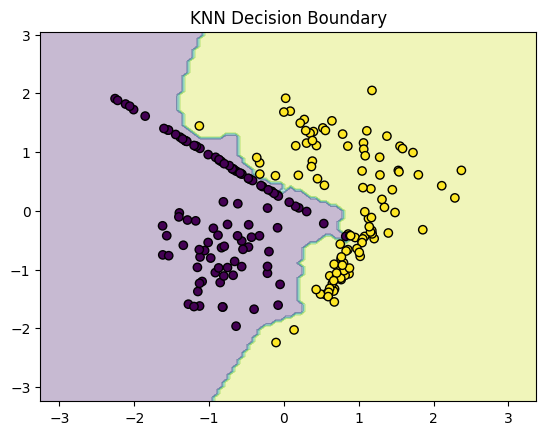


Curse of Dimensionality
Features: 2 Accuracy: 0.953
Features: 10 Accuracy: 0.82
Features: 50 Accuracy: 0.66
Features: 100 Accuracy: 0.653


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Generate dataset
X, y = make_classification(n_samples=300, n_features=2,
                           n_redundant=0, random_state=42)

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.3, random_state=42)

# Scale data
sc = StandardScaler()
Xtr = sc.fit_transform(Xtr)
Xte = sc.transform(Xte)

# Tune K
acc = []
for k in range(1, 16):
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(Xtr, ytr)
    score = accuracy_score(yte, m.predict(Xte))
    acc.append(score)
    print("K =", k, "Accuracy =", round(score, 3))

best_k = np.argmax(acc) + 1
print("Best K:", best_k)

# Plot accuracy
plt.plot(range(1, 16), acc, marker='o')
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.show()

# Decision boundary
m = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr, ytr)
xx, yy = np.meshgrid(
    np.linspace(Xtr[:, 0].min()-1, Xtr[:, 0].max()+1, 100),
    np.linspace(Xtr[:, 1].min()-1, Xtr[:, 1].max()+1, 100))

Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, edgecolors='black')
plt.title("KNN Decision Boundary")
plt.show()

# Curse of dimensionality
print("\nCurse of Dimensionality")
for d in [2, 10, 50, 100]:
    X, y = make_classification(n_samples=500, n_features=d,
                               n_informative=2, n_redundant=0,
                               random_state=42)
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.3, random_state=42)
    sc = StandardScaler()
    Xtr, Xte = sc.fit_transform(Xtr), sc.transform(Xte)
    m = KNeighborsClassifier(n_neighbors=5).fit(Xtr, ytr)
    print("Features:", d, "Accuracy:",
          round(accuracy_score(yte, m.predict(Xte)), 3))